In [1]:
%% MIT 18.03 Lecture 33: Eigenvalues, Eigenvectors & Normal Mode Saddle Dynamics
% Description: Simulates 2D state-space system u' = A*u via Control System Toolbox:
%              1) Benchmark Matrix: A = [-2, 1; -4, 3] with eigenvalues -1 and 2.
%              2) Extracts Normal Modes: u1(t) = e^{-t}*[1; 1] and u2(t) = e^{2t}*[1; 4].
%              3) Resolves IVP u(0) = [1; 0] -> u(t) = (4/3)*e^{-t}*[1; 1] - (1/3)*e^{2t}*[1; 4].
%              4) Visualizes Saddle Point phase portrait and asymptotic manifold alignment.
%
% % Required Toolboxes:
% %   - Control System Toolbox (ss, initial, pole, canon).
%
% % MBD Concept Mapping: Maps eigenvalues to system poles and eigenvectors to mode shapes.
% %                      Demonstrates modal decoupling (canon modal form) and saddle-point
% %                      separatrix behavior in unstable open-loop plants.


clear; clc; close all;


%% =========================================================================
%% Part 1: Eigen-Decomposition & Modal Realization (Sections [2]-[5])
%% =========================================================================
% Lecture Benchmark Matrix: A = [-2, 1; -4, 3]
A_mat = [-2,  1;
         -4,  3];


% Construct autonomous State-Space model via Control System Toolbox
sys_ss = ss(A_mat, zeros(2, 1), eye(2), zeros(2, 1));
sys_poles = pole(sys_ss);


% Obtain modal canonical form via Control System Toolbox 'canon'
[sys_modal, T_modal] = canon(sys_ss, 'modal');


% Exact integer eigenvectors derived in Lecture Section [4]:
lambda1 = -1.0; v1 = [1; 1]; % Stable normal mode direction
lambda2 =  2.0; v2 = [1; 4]; % Unstable normal mode direction


% Solve initial value problem u(0) = [1; 0] using eigenvector matrix V = [v1, v2]
u0 = [1; 0];
V_mat = [v1, v2];
c_coeffs = V_mat \ u0; % Solves [1, 1; 1, 4] * [c1; c2] = [1; 0] -> c1 = 4/3, c2 = -1/3


fprintf('=== MIT 18.03 Lecture 33 Eigenvalue & Modal Diagnostics ===\n');

=== MIT 18.03 Lecture 33 Eigenvalue & Modal Diagnostics ===

In [2]:
fprintf('System Matrix A              : [ %d, %d ; %d, %d ]\n', A_mat(1,1), A_mat(1,2), A_mat(2,1), A_mat(2,2));

System Matrix A              : [ -2, 1 ; -4, 3 ]

In [3]:
fprintf('Characteristic Polynomial    : lambda^2 - %.1f*lambda + (%.1f) = 0\n', trace(A_mat), det(A_mat));

Characteristic Polynomial    : lambda^2 - 1.0*lambda + (-2.0) = 0

In [4]:
fprintf('Eigenvalue 1 (Stable Mode)   : lambda_1 = %+.2f, Eigenvector v_1 = [%d; %d]\n', lambda1, v1(1), v1(2));

Eigenvalue 1 (Stable Mode)   : lambda_1 = -1.00, Eigenvector v_1 = [1; 1]

In [5]:
fprintf('Eigenvalue 2 (Unstable Mode) : lambda_2 = %+.2f, Eigenvector v_2 = [%d; %d]\n', lambda2, v2(1), v2(2));

Eigenvalue 2 (Unstable Mode) : lambda_2 = +2.00, Eigenvector v_2 = [1; 4]

In [6]:
fprintf('Initial Condition u(0)       : [%d; %d]\n', u0(1), u0(2));

Initial Condition u(0)       : [1; 0]

In [7]:
fprintf('Modal Weights [c1; c2]       : c1 = %+.4f (4/3), c2 = %+.4f (-1/3)\n', c_coeffs(1), c_coeffs(2));

Modal Weights [c1; c2]       : c1 = +1.3333 (4/3), c2 = -0.3333 (-1/3)

In [8]:
fprintf('Diagonalized Modal Matrix A_m:\n');

Diagonalized Modal Matrix A_m:

In [9]:
disp(sys_modal.A);

    -1     0
     0     2

In [10]:
fprintf('===========================================================\n\n');


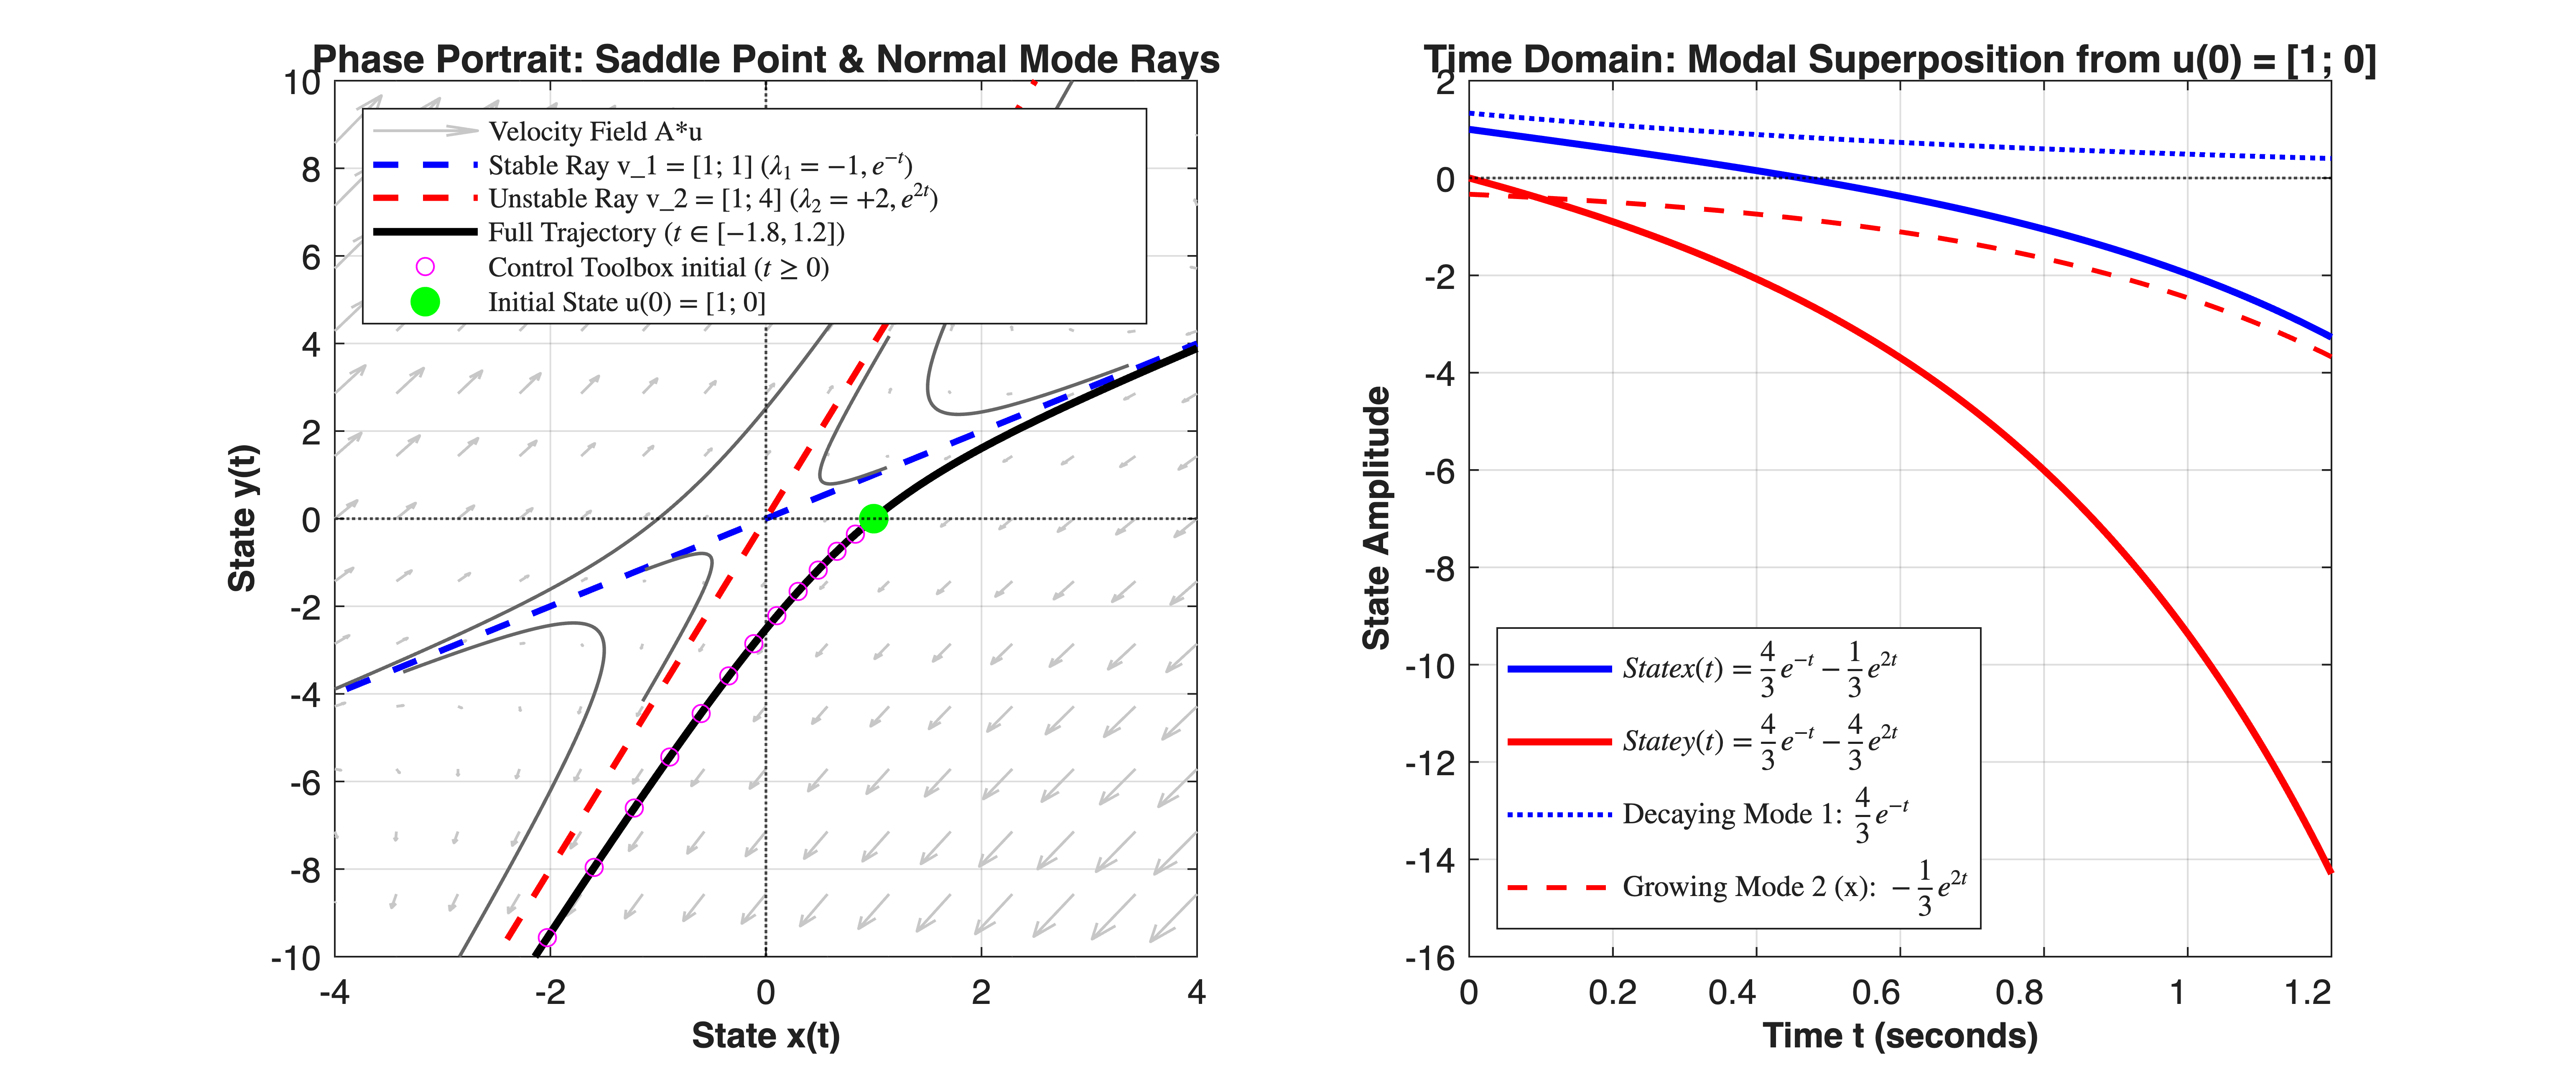

In [11]:


%% =========================================================================
%% Part 2: Time-Domain & Phase-Plane Simulation
%% =========================================================================
% Forward simulation from t = 0 to 1.2 using Control System Toolbox 'initial'
t_pos = linspace(0, 1.2, 500);
[u_sim_pos, ~] = initial(sys_ss, u0, t_pos);


% Analytical modal superposition over bidirectional time t in [-2.0, 1.2]
% to illustrate Lecture Section [5] asymptotic behavior for negative and positive t
t_full = linspace(-1.8, 1.2, 800);
u_mode1 = c_coeffs(1) * exp(lambda1 * t_full) .* v1; % (4/3)*e^{-t}*[1; 1]
u_mode2 = c_coeffs(2) * exp(lambda2 * t_full) .* v2; % (-1/3)*e^{2t}*[1; 4]
u_total = u_mode1 + u_mode2;


figure('Color', [1 1 1], 'Position', [80, 80, 1200, 500]);


% Subplot 1: Phase Plane Portrait (Saddle Point, Ray Solutions & Asymptotics)
subplot(1, 2, 1);
hold on; grid on; box on;
xline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');
yline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');


% Background velocity vector field
[X_grid, Y_grid] = meshgrid(linspace(-4, 4, 15), linspace(-10, 10, 15));
U_vel = A_mat(1,1)*X_grid + A_mat(1,2)*Y_grid;
V_vel = A_mat(2,1)*X_grid + A_mat(2,2)*Y_grid;
quiver(X_grid, Y_grid, U_vel, V_vel, 'Color', [0.78 0.78 0.78], ...
       'LineWidth', 0.8, 'DisplayName', 'Velocity Field A*u');


% Plot Eigenvector Invariant Rays (Normal Modes)
s_ray = linspace(-8, 8, 100);
plot(s_ray * v1(1), s_ray * v1(2), 'b--', 'LineWidth', 1.8, ...
     'DisplayName', 'Stable Ray v_1 = [1; 1] ($\lambda_1 = -1, e^{-t}$)');
plot(s_ray * v2(1), s_ray * v2(2), 'r--', 'LineWidth', 1.8, ...
     'DisplayName', 'Unstable Ray v_2 = [1; 4] ($\lambda_2 = +2, e^{2t}$)');


% Plot bidirectional trajectory passing through u(0) = [1; 0]
plot(u_total(1, :), u_total(2, :), 'k-', 'LineWidth', 2.2, ...
     'DisplayName', 'Full Trajectory ($t \in [-1.8, 1.2]$)');
plot(u_sim_pos(:, 1), u_sim_pos(:, 2), 'mo', 'MarkerIndices', 1:35:length(t_pos), ...
     'MarkerSize', 5, 'DisplayName', 'Control Toolbox initial ($t \ge 0$)');
plot(u0(1), u0(2), 'go', 'MarkerFaceColor', 'g', 'MarkerSize', 8, ...
     'DisplayName', 'Initial State u(0) = [1; 0]');


% Plot additional family of saddle trajectories
ic_family = [-1, 0;  0.5, 1;  -0.5, -1;  1.5, 3;  -1.5, -3]';
t_fam = linspace(-1.2, 0.9, 300);
for k = 1:size(ic_family, 2)
    c_fam = V_mat \ ic_family(:, k);
    u_fam = c_fam(1)*exp(lambda1*t_fam).*v1 + c_fam(2)*exp(lambda2*t_fam).*v2;
    plot(u_fam(1, :), u_fam(2, :), 'Color', [0.4 0.4 0.4], 'LineWidth', 1.0, 'HandleVisibility', 'off');
end


xlabel('State x(t)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State y(t)', 'FontSize', 10, 'FontWeight', 'bold');
title('Phase Portrait: Saddle Point & Normal Mode Rays', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'northwest', 'FontSize', 8, 'Interpreter','latex');
xlim([-4, 4]); ylim([-10, 10]);


% Subplot 2: Time-Domain Modal Decomposition for t >= 0
subplot(1, 2, 2);
hold on; grid on; box on;


plot(t_pos, u_sim_pos(:, 1), 'b-', 'LineWidth', 2.0, 'DisplayName', '$State x(t) = \frac{4}{3}e^{-t} - \frac{1}{3}e^{2t}$');
plot(t_pos, u_sim_pos(:, 2), 'r-', 'LineWidth', 2.0, 'DisplayName', '$State y(t) = \frac{4}{3}e^{-t} - \frac{4}{3}e^{2t}$');
plot(t_pos, (4/3)*exp(-t_pos), 'b:', 'LineWidth', 1.4, 'DisplayName', 'Decaying Mode 1: $\frac{4}{3}e^{-t}$');
plot(t_pos, (-1/3)*exp(2*t_pos), 'r--', 'LineWidth', 1.4, 'DisplayName', 'Growing Mode 2 (x): $-\frac{1}{3}e^{2t}$');


yline(0, 'k:', 'LineWidth', 0.8, 'HandleVisibility', 'off');
xlabel('Time t (seconds)', 'FontSize', 10, 'FontWeight', 'bold');
ylabel('State Amplitude', 'FontSize', 10, 'FontWeight', 'bold');
title('Time Domain: Modal Superposition from u(0) = [1; 0]', 'FontSize', 11, 'FontWeight', 'bold');
legend('Location', 'southwest', 'FontSize', 8.5, 'Interpreter','latex');
xlim([0, 1.2]);